# Tuokkola et al. near-millisecond transmon sample (Aalto / VTT): a Quantcore-PDK rebuild, step by step

**Source:** M. Tuokkola, Y. Sunada, H. Kivijärvi, J. Albanese, L. Grönberg, J.-P. Kaikkonen, V. Vesterinen,
J. Govenius, M. Möttönen, *Methods to achieve near-millisecond energy relaxation and dephasing times for a
superconducting transmon qubit* (arXiv 2407.18778).
- Data and GDS: Zenodo record 14651787, **CC BY 4.0**, read from the local copy `components/Zenodo_files/`.
- The sample: `sample.gds`, chip `EITR2` (10 × 10 mm, centred on (0, 0)); its layers are copied into
  `examples/designs/community/tuokkola_near_ms_transmon_sample.oas`.

Spec: `docs/designs/community/tuokkola_near_ms_transmon.md`.

**What the chip is (read from the GDS):** four floating two-pad transmons, Q1/Q3 with SQUIDs and Q2/Q4 with single
junctions. Pockets are 800 × 1000 µm, pads 400 × 300 µm with a 20 µm gap, and each has a coupler bar. Readout goes
through four λ/4s, each with 900 µm of coupled line on one U-shaped λ/2 Purcell filter. The filter sits between an
input finger capacitor and an interdigital output capacitor (feed CPW 21/11 µm). Two drive lines are each shared by
a pair of qubits. The whole ground plane carries a hole grid.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source (`sample.gds`, EITR2) | this rebuild |
|---|---|---|
| die and frame | 10 × 10 mm, labels `EITR2` / `1-0`, corner marks | PDK frame on the same 10 × 10 mm die, device ID `EITR2-QCT` |
| stack | sapphire | PDK sapphire 650 µm, εr 10.25 |
| qubits | two-pad transmons, Q1/Q3 SQUID, Q2/Q4 single junction | `metal:TransmonPocket6` with the GDS sizes; Quantcore trilayer SQUIDs / junctions sized for the measured f_q (R_n and f_q outside the PDK margins are flagged, not retuned) |
| Purcell filter | U-shaped λ/2 between two capacitors | a qcc CPW route on the GDS's runs between two `FingerCapacitorSquare`s with the GDS's finger counts |
| readouts | four meandered λ/4s, 900 µm coupled to the filter | qcc λ/4 hangers on the filter, centred where the GDS has them (`near=`) |
| pads | launchpads 850–940 µm from the die edge | **PDK pad rule**: outer etch `frame.pad_edge` = 100 µm from the die edge |
| placement | circuit left of centre (the right edge holds a junction test column) | the test column is not rebuilt, so **the circuit is centred** in the die |
| cheese | a whole-chip hole grid: 20 µm squares, 40 µm pitch, ≥ 80 µm from all etch, ≈ 0.3 mm from the chip edge | **the original wins**: the same grid as the chip's `cheese` rule, drawn by the build and kept in the mask (no PDK band) |
| not rebuilt | labels, junction test column, an unconnected meander | – |

The measured qubit and readout frequencies are the targets (Design 2 and 8; to be checked against the paper). The last
snapshots render the sample's own chip next to the rebuild.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the die with the sample's hole grid, the four pocket transmons with their sized junctions, the
Purcell filter between its two capacitors, the four λ/4 hangers on the filter, the centring of that circuit, the four
launchpads on the PDK pad rule, the feed and drive lines, and then the whole chip (the sim groups and targets, the
save). The order is the geometry's: the circuit is centred before the pads exist, and the pads take their positions
from the shifted origin. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `tuokkola_near_ms_transmon.v1.ipynb`; both save the same
`tuokkola_near_ms_transmon.json`.

## Setup

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change shows up live; with `QCC_LIVE=0` (tests, batch
runs) the snapshots are rendered headless. `sizing_md` tabulates the junction sizing against the PDK junction rule.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.circuit.bridges import size_junction, tl_resonator
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)


def sizing_md(sizing):
    """Trilayer junction sizing (``circuit.bridges.size_junction``) against the PDK junction rule."""
    rows = ["| qubit | f_q target (GHz) | C_Σ (fF) | L_J (nH) | R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |",
            "|---|---|---|---|---|---|---|"]
    for name, s in sizing.items():
        rows.append(f"| {name} | {s.f_q_GHz:.3f} | {s.c_sigma_fF:.1f} | {s.lj_nH:.2f} | {s.rn_kohm:.1f} | "
                    f"{s.f_q_drawn_GHz:.3f} | {'yes' if s.rn_in_window else 'no'} |")
    return "\n".join(rows)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on. The frame and the cheese are drawn by the chip build, the pad rule by `edge=`, the junctions by
`trilayer_junction`; the PDK design warnings come out of the DRC.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). **The order here is fixed by the geometry** (it is the source's): the circuit is centred before the pads
exist, because the pads are pinned to the die edges and would drag the centring, and the pads, the feed lines and the
drive lines are placed from the source origin *after* that shift (`X0, Y0`); so the bond pads come in segment 6, not
2. The qubits come before the filter, as in the source; no position there depends on that order.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the PDK frame and the sample's hole grid as the chip's cheese rule |
| 2 | qubit placement: the four pocket transmons (Q1/Q3 SQUIDs, Q2/Q4 single junctions), sized for the measured f_q |
| 3 | the readout line: the two filter capacitors and the U-shaped λ/2 Purcell filter between them |
| 4 | the readouts: the four λ/4 hangers, 900 µm coupled to the filter |
| 5 | the PDK placement: the circuit (segments 2–4) centred in the die |
| 6 | the bond pads: four launchpads, each 100 µm from its nearest die edge |
| 7 | the routing: the two feed lines to the filter capacitors and the two shared drive lines |
| 8 | the whole chip: the sim groups and the measured targets, the save |

## Design 1 · The die and its frame

The sample is a 10 × 10 mm chip, so the rebuild keeps that die (the box is in µm; Designer = source + (5000, 5000)).
The PDK draws its frame round it: the L dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary
(100/0) and the device ID `EITR2-QCT` on a free edge.

**Cheese.** The sample's ground plane has its own hole grid (`sample.gds`: 20 µm squares on a 40 µm pitch, at least
80 µm from all etch, the field reaching to 0.29–0.39 mm from the chip edge), so the original wins: the chip carries
that grid as its `cheese` rule (`size`, `gap`, `rows`, `clearance`, `edge`) and the build draws it instead of the PDK
band (layout, snapshots, KLive and the mask). The rule's `clearance` is measured from the 3/0 keep-out, which already
adds the PDK route margin (10 µm) round each CPW, so 80 − 10 = 70 µm keeps the holes 80 µm from the line etch, as in
the sample (and 94 µm from the pockets, whose keep-out margin is 24 µm). `edge` 300 µm is the sample's margin to the
chip edge.

chip cheese rule: {'size': 20.0, 'gap': 20.0, 'rows': 1000, 'clearance': 70.0, 'edge': 300.0}


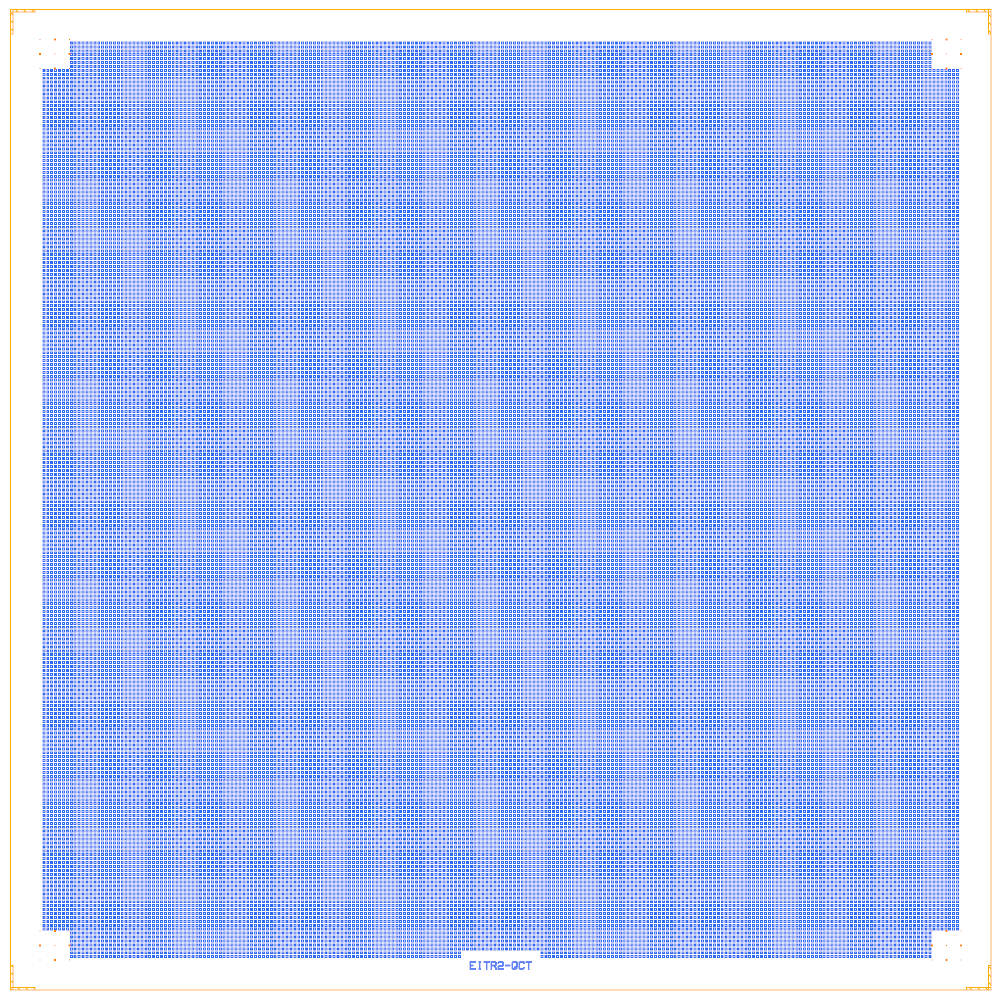

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/tuokkola_near_ms_transmon_die.png')

In [5]:
from quantcore_circuits.pdk import get_pdk

X0 = Y0 = 5000.0                                   # source chip (10 × 10 mm) is centred on (0, 0)
HOLES = {"size": 20.0, "gap": 20.0, "rows": 1000,  # the sample's grid: 20 µm squares on a 40 µm pitch,
         "clearance": 80.0 - get_pdk().keepout.route_margin,   # 80 µm from the line etch (3/0 adds 10 µm)
         "edge": 300.0}                            # ≈ the sample's margin to the chip edge
d = Designer("tuokkola_near_ms_transmon", box=(0, 0, 10000, 10000),
             chip={"name_chip": "EITR2-QCT", "cheese": HOLES}, live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
layout_step(d, OUT / "tuokkola_near_ms_transmon_die.png", size=(1000, 1000), width=360)

## Design 2 · Qubit placement: four pocket transmons, junctions sized for the measured f_q

**Targets and junction sizing.** The measured qubit frequencies (paper, first cooldown) set the junctions:
`size_junction(f_q, C_Σ, n)` finds the L_J that gives f_q at the pocket's LOM C_Σ (96 fF, from the netlist in Check 2),
for one junction (Q2, Q4) or a symmetric SQUID (n = 2: Q1, Q3), and the R_n and finger sizes of the drawn trilayer
junction. These qubits sit at 2.9–4.6 GHz, at or below the PDK's 4–8 GHz band, so every R_n lands above the 40–50 kΩ
window (75–188 kΩ as drawn; for the SQUIDs, the device's parallel R_n). Following the project rule they are flagged (DRC `pdk_rn`, `pdk_fq`), not retuned.

In [6]:
SITES = {  # name: ((x, y) source µm, rot, SQUID?, f_q target GHz (paper, first cooldown))
    "Q1": ((-100, 2513), 0, True, 4.047),
    "Q2": ((1400, 2513), 0, False, 2.890),
    "Q3": ((1400, -2513), 180, True, 4.593),
    "Q4": ((-100, -2513), 180, False, 3.295),
}
C_SIGMA = 96.0                                     # fF: LOM C_Σ of this pocket (Check 2), sizes the junctions
SIZING = {q: size_junction(f, C_SIGMA, n=2 if sq else 1) for q, (_, _, sq, f) in SITES.items()}
display(Markdown(sizing_md(SIZING)))

| qubit | f_q target (GHz) | C_Σ (fF) | L_J (nH) | R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |
|---|---|---|---|---|---|---|
| Q1 | 4.047 | 96.0 | 14.62 | 97.7 | 4.135 | no |
| Q2 | 2.890 | 96.0 | 27.60 | 184.4 | 2.865 | no |
| Q3 | 4.593 | 96.0 | 11.48 | 76.7 | 4.647 | no |
| Q4 | 3.295 | 96.0 | 21.58 | 144.2 | 3.339 | no |

**The qubits.** `metal:TransmonPocket6` (Quantum Metal's pocket transmon through the `metal:` wrapper) with the GDS's
sizes: pads 400 × 300 µm, gap 20 µm, pocket 800 × 1000 µm. The coupler bar is a centred 400 × 20 µm connection pad
40 µm below the pad, its 11/5 µm lead running to the pocket edge (the port `readout`). `trilayer_junction(...,
squid=...)` returns the cell parameters that draw the Quantcore SQUID or single junction (fingers 2/0 + 4/0, spacer
50/0 + 51–53/0) and the junction values the LOM uses.

Q1 Quantcore Squid {'Lj_nH': 14.03, 'Cj_fF': 7.2}
Q2 Quantcore Junction {'Lj_nH': 28.0601, 'Cj_fF': 3.6}
Q3 Quantcore Squid {'Lj_nH': 11.224, 'Cj_fF': 9.0}
Q4 Quantcore Junction {'Lj_nH': 21.0451, 'Cj_fF': 4.8}


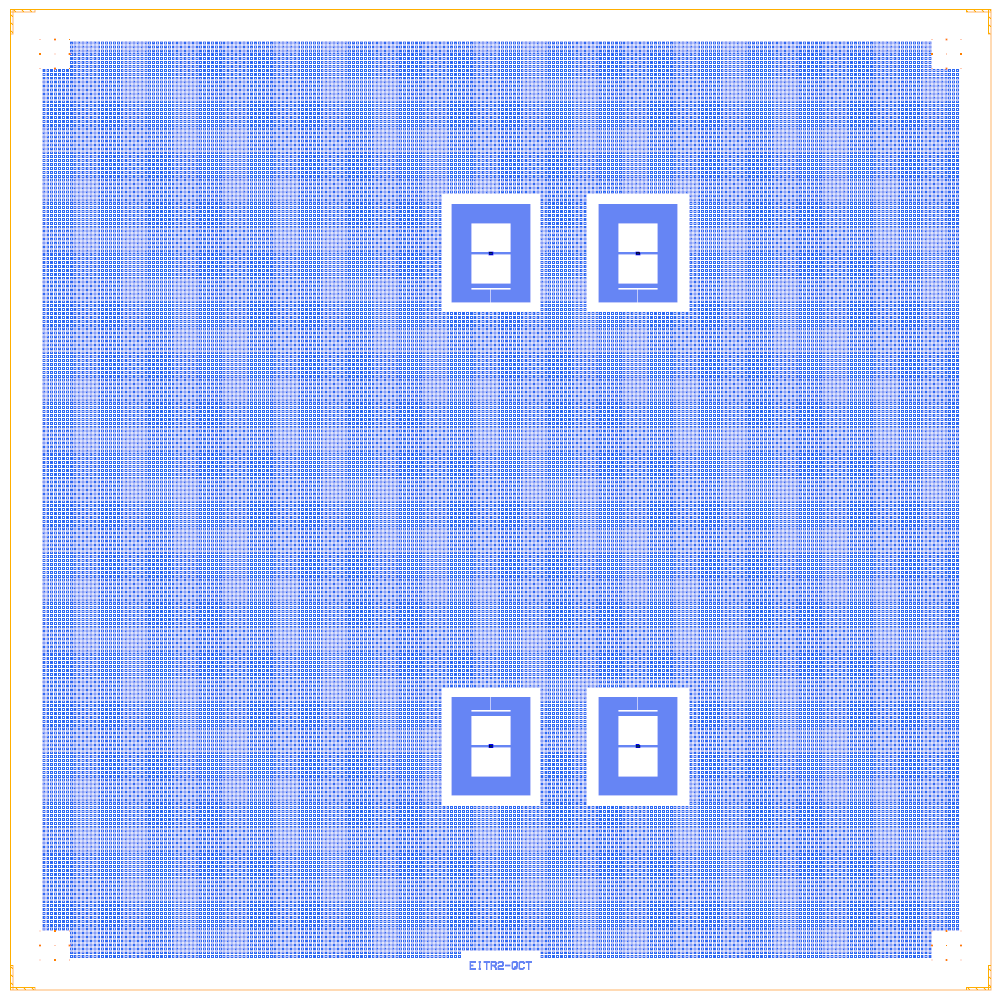

**On the chip so far:** 0 pads · 4 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `Q1`, `Q2`, `Q3`, `Q4`.

WindowsPath('examples/designs/community/tuokkola_near_ms_transmon_s2_qubits.png')

In [7]:
POCKET = dict(pad_width=400, pad_height=300, pad_gap=20, pocket_width=800, pocket_height=1000,
              connection_pads=dict(readout=dict(loc_W=0, loc_H=-1, pad_width=400, pad_height=20, pad_gap=40,
                                                pad_cpw_shift=0, pad_cpw_extent=0, cpw_width=11, cpw_gap=5,
                                                cpw_extend=0)))
q = {}
with d.batch():
    for name, ((x, y), rot, squid, f) in SITES.items():
        params, jj = trilayer_junction("metal:TransmonPocket6", lj_nH=SIZING[name].lj_nH, squid=squid)
        q[name] = d.add(name, "metal:TransmonPocket6", at=(X0 + x, Y0 + y), rot=rot, junction=jj, **POCKET, **params)
        print(name, params["junction_type"], jj)
layout_step(d, OUT / "tuokkola_near_ms_transmon_s2_qubits.png", size=(1000, 1000), width=360)

## Design 3 · Readout: the Purcell filter between its two capacitors

**The filter capacitors.** Both are KQC `FingerCapacitorSquare`s with the GDS's finger counts and lengths, on the
source's 21/11 µm feed CPW: the input one (2 fingers × 100 µm) at the top left, the interdigital output one
(7 fingers × 500 µm) at the bottom left. Their ports `a` (feed side) and `b` (filter side) carry the routes.

**The filter** is a plain CPW (`type="cpw"`, no meander) from `CIN.b` along the top run, round the U at x = +1816 µm
(bend radius 180 µm) and back along the bottom run to `COUT.b`: the waypoints are the GDS's.

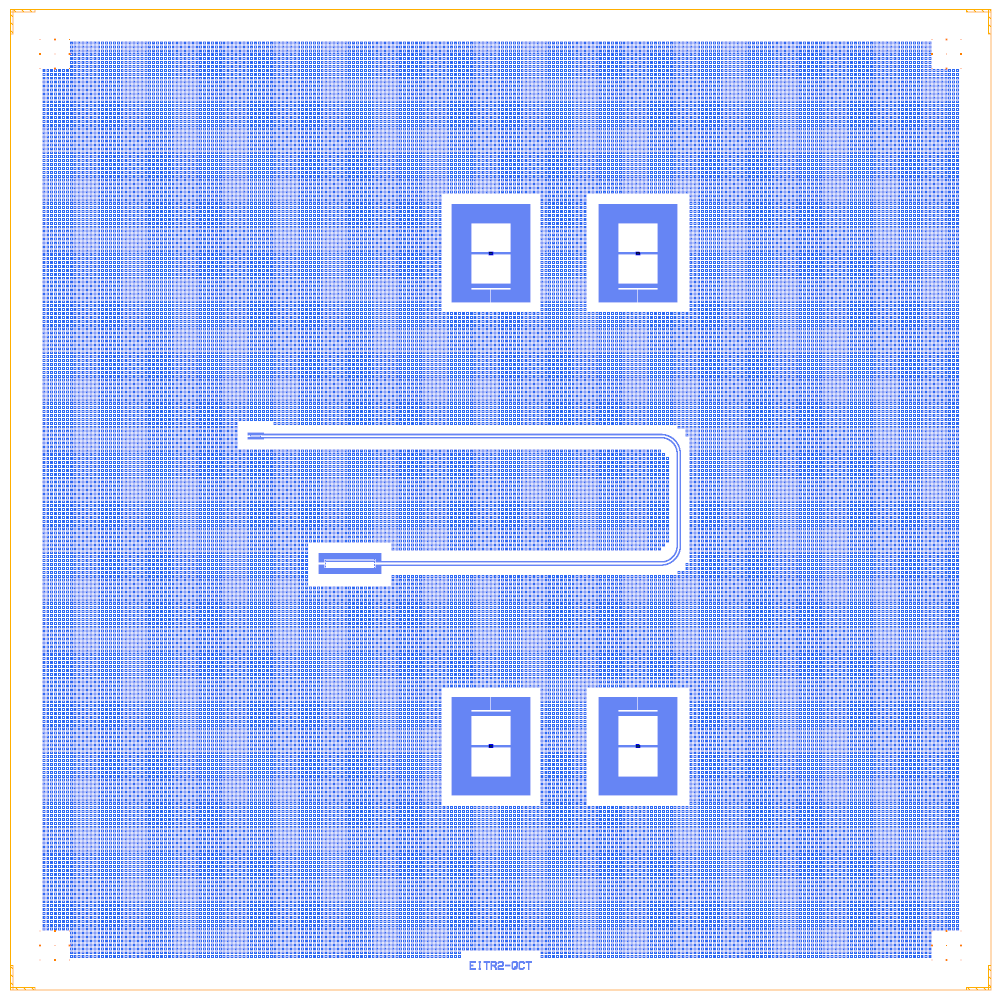

**On the chip so far:** 0 pads · 4 qubits · 2 other components · 1 routes · 0 declared couplings. **This step added** 2 component(s) `CIN`, `COUT` and 1 route(s) `PF`.

WindowsPath('examples/designs/community/tuokkola_near_ms_transmon_components.png')

In [8]:
FEED = dict(a=21, b=11)                            # the source's filter / feed CPW
Y_TOP, Y_BOT, X_U = Y0 + 650, Y0 - 650, X0 + 1816  # filter runs and its U (from the GDS)
with d.batch():
    cin = d.add("CIN", "FingerCapacitorSquare", at=(X0 - 2500, Y_TOP), finger_number=2, finger_width=10,
                finger_gap=5, finger_length=100, finger_gap_end=5, ground_padding=20, **FEED)
    cout = d.add("COUT", "FingerCapacitorSquare", at=(X0 - 1536, Y_BOT), finger_number=7, finger_width=11,
                 finger_gap=4, finger_length=500, finger_gap_end=4, ground_padding=56, **FEED)
with d.batch():
    pf = d.route("PF", cin.b, cout.b, type="cpw", nodes=[(X_U, Y_TOP), (X_U, Y_BOT)], r=180, **FEED)   # the U filter
layout_step(d, OUT / "tuokkola_near_ms_transmon_components.png", size=(1000, 1000), width=360)

## Design 4 · Readout: four λ/4 hangers on the filter

**The readouts** are λ/4s on the PDK stack: L = v_ph / 4f for the 11/5 µm CPW, −7 % for the pull of the coupler bar's
C_g and of the hanger, as calibrated once in the LOM. Each starts at its qubit's coupler bar, meanders (r 50 µm) and
ends in `pf.hanger(...)`: 900 µm of line coupled to the filter across a 31 µm ground strip, shorted at its far end.
`near=(x, y)` centres the coupler at the filter point nearest (x, y): 450 µm left of the qubit, as in the GDS. A coupler
given by `near=` stays put when the filter's start moves; `direction` sets which end is shorted. The router adds one KQC `Meander` for whatever each
length leaves over its path (with no more turns than keep each turn at least its 50 µm bend radius wide).

{'PF': 8412.0, 'R_Q1': 5017.6, 'R_Q2': 4911.0, 'R_Q3': 4809.6, 'R_Q4': 4711.6}
λ/4 targets (µm): {'Q1': 5017.6, 'Q2': 4911.0, 'Q3': 4809.6, 'Q4': 4711.6}


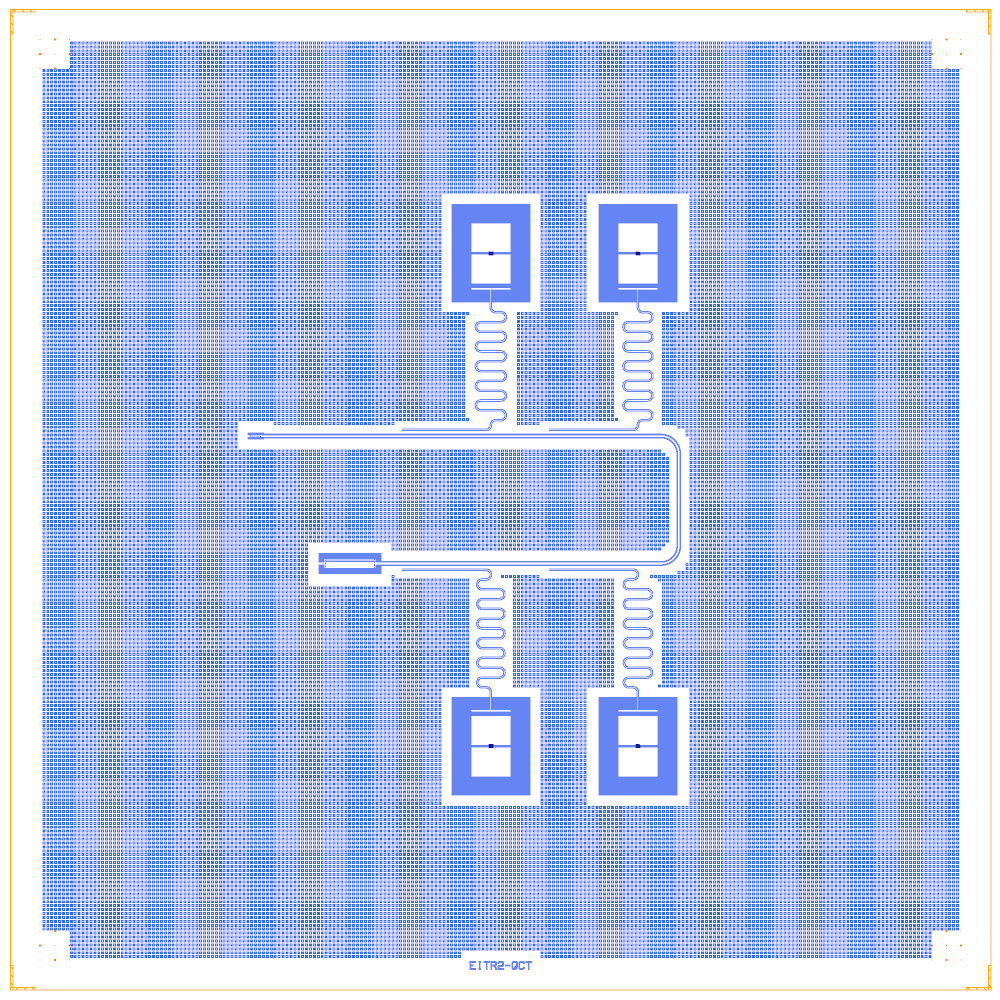

**On the chip so far:** 0 pads · 4 qubits · 2 other components · 5 routes · 0 declared couplings. **This step added** 4 route(s) `R_Q1`, `R_Q2`, `R_Q3`, `R_Q4`.

WindowsPath('examples/designs/community/tuokkola_near_ms_transmon_s4_readouts.png')

In [9]:
F_R = dict(Q1=5.85, Q2=5.977, Q3=6.103, Q4=6.23)  # paper: 5.85–6.23 GHz; assigned by the GDS resonator lengths
VP = tl_resonator(4500, 11, 5)["vp_m_s"]           # PDK stack (sapphire), 11/5 µm CPW (the source's readout CPW)
L_RO = {q_: round(VP / (4 * f * 1e9) * 1e6 * 0.930, 1) for q_, f in F_R.items()}   # λ/4, −7 % (C_g + hanger pull)
HG = dict(length=900, side="left", ground_gap=31, end="short")
with d.batch():
    for name, ((x, y), rot, squid, f) in SITES.items():
        near = (X0 + x - 450, Y_TOP if y > 0 else Y_BOT)                  # coupler centre: 450 µm left of the qubit
        d.route(f"R_{name}", q[name].readout,
                pf.hanger(near=near, direction="backward" if y > 0 else "forward", **HG),
                meander=L_RO[name], r=50, a=11, b=5)
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
print("λ/4 targets (µm):", L_RO)
layout_step(d, OUT / "tuokkola_near_ms_transmon_s4_readouts.png", size=(1000, 1000), width=360)

## Design 5 · PDK placement: centre the circuit, before the pads

The sample's circuit sits left of the die centre because its right edge holds a junction test column,
which the rebuild does not draw. `center_in_die(d)` measures the bounding box of every instance and route (the qubits,
the capacitors, the filter and the readouts so far) and shifts all of them so that box is centred. This is done before
the pads (Design 6): they are pinned to the die edges by the pad rule and would drag the centring.

shift applied (µm): (383.2, 0.0)


content box after centring: (2800.7,1987;7199.2,8013)


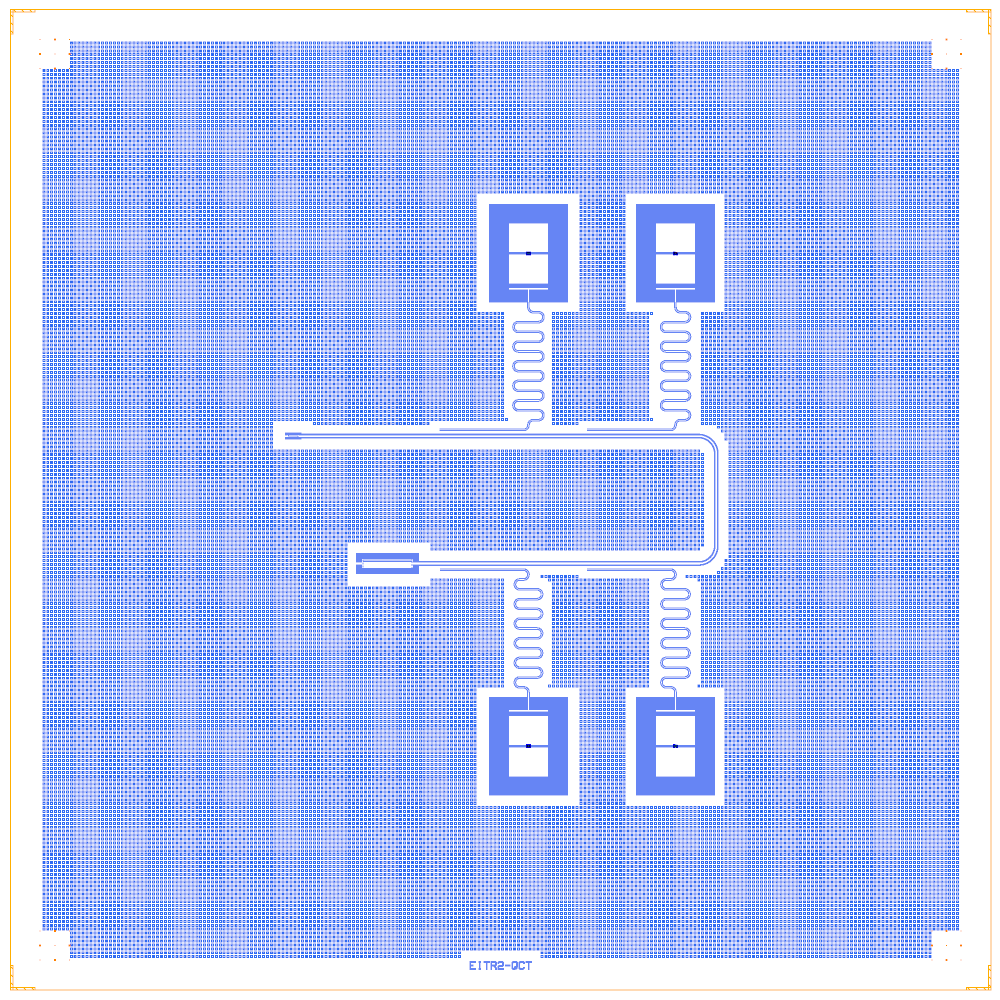

**On the chip so far:** 0 pads · 4 qubits · 2 other components · 5 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/tuokkola_near_ms_transmon_s5_centred.png')

In [10]:
shift = center_in_die(d)
print("shift applied (µm):", shift)
X0, Y0 = X0 + shift[0], Y0 + shift[1]             # the source origin in Designer coordinates from here on
Y_TOP, Y_BOT = Y0 + 650, Y0 - 650
print("content box after centring:", content_box(d))
layout_step(d, OUT / "tuokkola_near_ms_transmon_s5_centred.png", size=(1000, 1000), width=360)

## Design 6 · Bond pads: four launchpads and the PDK pad rule

**The pad rule.** The sample's launchpads sit 850–940 µm inside the die. The PDK puts every bond pad and launcher with
the outer edge of its etch **`frame.pad_edge` = 100 µm from the die edge**. `edge="auto"` slides each pad
perpendicular to its nearest die edge until that holds and keeps its position along the edge: the two filter ports go
to the west edge at the filter's heights, the two drive pads to the north and south edges above and below the gap
between the qubit pairs. `pads_md(d)` lists each pad's distance to the nearest edge. Their positions
come from `X0, Y0`, the source origin after the shift of Design 5.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP_IN | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_OUT | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_DT | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| LP_DB | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

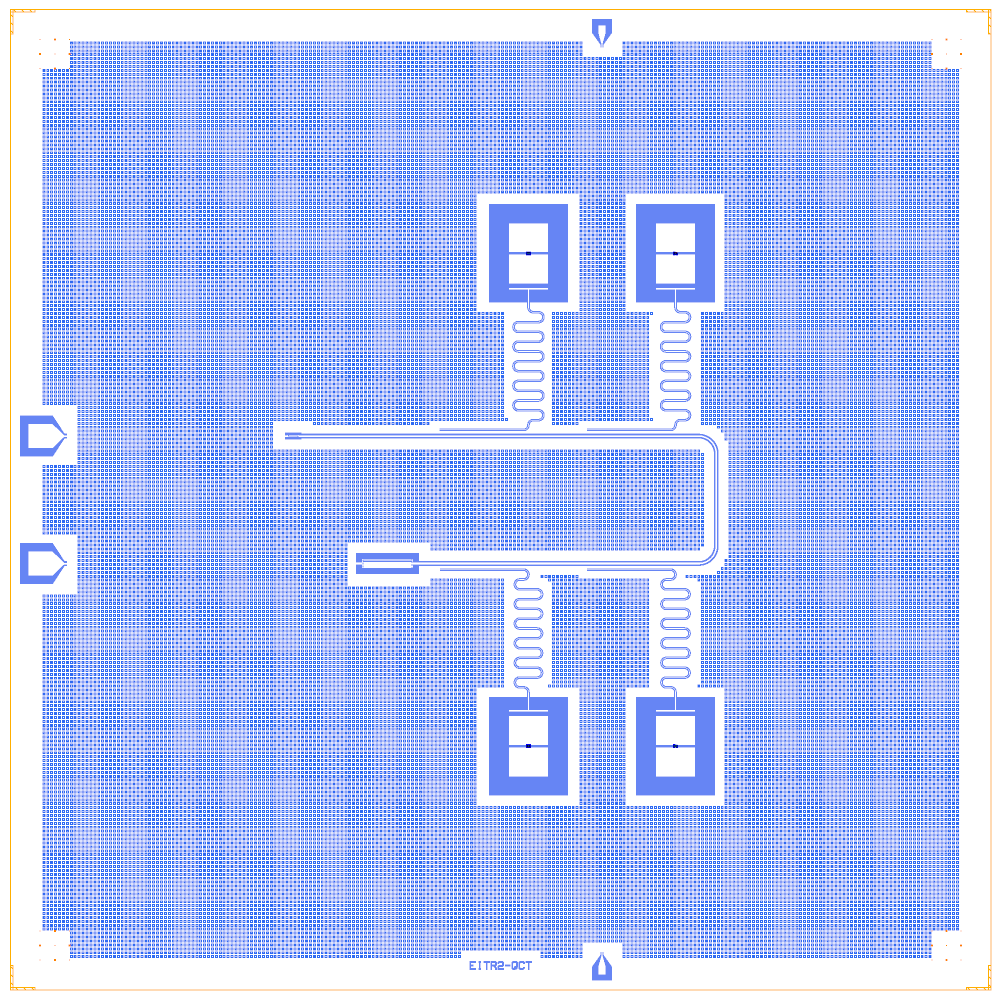

**On the chip so far:** 4 pads · 4 qubits · 2 other components · 5 routes · 0 declared couplings. **This step added** 4 component(s) `LP_IN`, `LP_OUT`, `LP_DT`, `LP_DB`.

WindowsPath('examples/designs/community/tuokkola_near_ms_transmon_s6_pads.png')

In [11]:
LP_FEED = dict(trace_width=21, trace_gap=11, pad_width=250, pad_height=250, pad_gap=80, taper_height=120)
with d.batch():
    lp_in = d.add("LP_IN", "metal:LaunchpadWirebond", at=(X0 - 3700, Y_TOP), edge="auto", **LP_FEED)
    lp_out = d.add("LP_OUT", "metal:LaunchpadWirebond", at=(X0 - 3700, Y_BOT), edge="auto", **LP_FEED)
    lp_dt = d.add("LP_DT", "metal:LaunchpadWirebond", at=(X0 + 650, Y0 + 3800), rot=-90, edge="auto",
                  trace_width=11, trace_gap=5)
    lp_db = d.add("LP_DB", "metal:LaunchpadWirebond", at=(X0 + 650, Y0 - 3800), rot=90, edge="auto",
                  trace_width=11, trace_gap=5)
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "tuokkola_near_ms_transmon_s6_pads.png", size=(1000, 1000), width=360)

## Design 7 · Routing: the feed lines and the two drive lines

**Feed and drive lines.** The feed lines join the launchpads to the filter capacitors; with the pads at the edge they
are longer than in the sample (a 50 Ω line: its length does not set any frequency). The two drive lines, each shared
by a qubit pair, end open (5 µm gap) between the pockets: `Designer.free_end(at, dir, term)` is a route end that is not
a port. The sim groups and the targets follow in Design 8.

{'PF': 8412.0, 'R_Q1': 5017.6, 'R_Q2': 4911.0, 'R_Q3': 4809.6, 'R_Q4': 4711.6, 'FEED_IN': 2225.7, 'FEED_OUT': 2953.2, 'DRIVE_T': 1947.5, 'DRIVE_B': 1947.5}


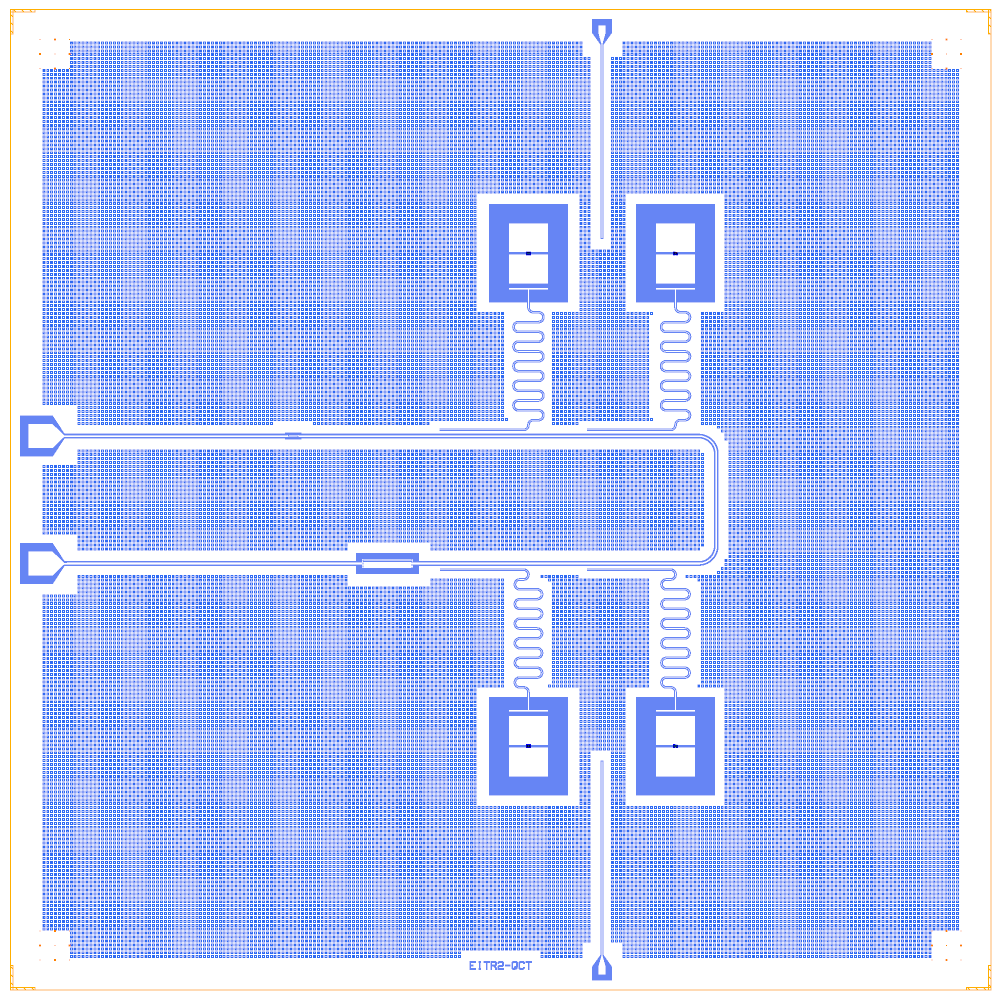

**On the chip so far:** 4 pads · 4 qubits · 2 other components · 9 routes · 0 declared couplings. **This step added** 4 route(s) `FEED_IN`, `FEED_OUT`, `DRIVE_T`, `DRIVE_B`.

WindowsPath('examples/designs/community/tuokkola_near_ms_transmon_s7_lines.png')

In [12]:
with d.batch():
    d.route("FEED_IN", lp_in.tie, cin.a, **FEED)
    d.route("FEED_OUT", cout.a, lp_out.tie, **FEED)
    d.route("DRIVE_T", lp_dt.tie, Designer.free_end((X0 + 650, Y0 + 2667.5), dir=90, term=5), a=11, b=5)
    d.route("DRIVE_B", lp_db.tie, Designer.free_end((X0 + 650, Y0 - 2667.5), dir=-90, term=5), a=11, b=5)
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "tuokkola_near_ms_transmon_s7_lines.png", size=(1000, 1000), width=360)

## Design 8 · The whole chip: sim groups, targets, save

**Sim groups and targets:** one sim group per qubit with its readout and the whole filter chain (`Q1R` … `Q4R`, the
default analyses: eigenmode / EPR and Q3D C-matrix); the targets are the paper's measured qubit and readout frequencies
(f_q 4.047 / 2.890 / 4.593 / 3.295 GHz, f_r 5.85–6.23 GHz). The circuit was centred in Design 5.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's, the `.v1` notebook's): the segments above changed how the chip is built, not the chip, so it should say
*same design*. The file keeps the previous key order (here every instance and route comes in the v1's order), so `git diff` stays empty.

**Same design as before:** `examples/designs/community/tuokkola_near_ms_transmon.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer tuokkola_near_ms_transmon: 10 instances, 9 routes, live=False> → examples\designs\community\tuokkola_near_ms_transmon.json


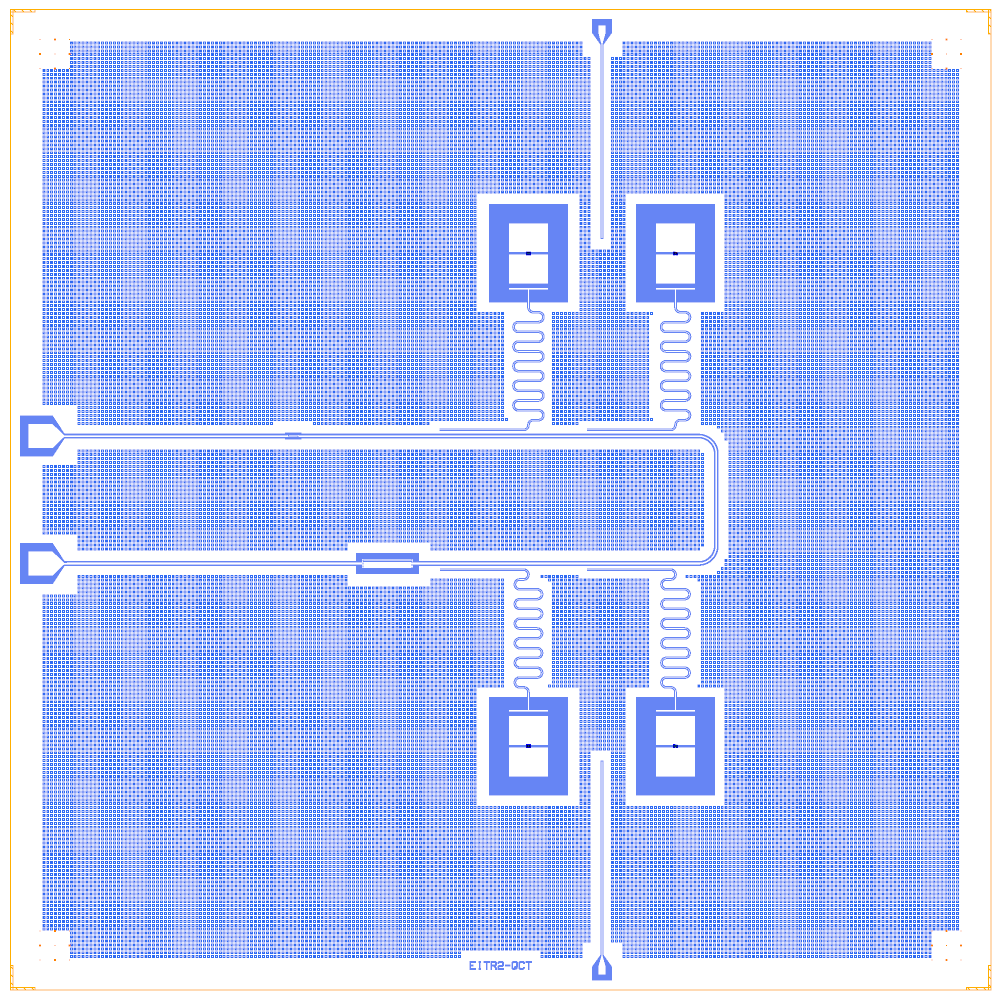

**On the chip so far:** 4 pads · 4 qubits · 2 other components · 9 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/tuokkola_near_ms_transmon_routes.png')

In [13]:
with d.batch():
    for name in SITES:
        d.sim_group(f"{name}R", [name, f"R_{name}", "PF", "CIN", "COUT"])
    d.targets(**{n: {"f_q_GHz": f} for n, (_, _, _, f) in SITES.items()},
              **{f"R_{n}": {"f_GHz": f} for n, f in F_R.items()})
rebuild(d)
DESIGN, same = save_design(d, OUT / "tuokkola_near_ms_transmon.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "tuokkola_near_ms_transmon_routes.png", size=(1000, 1000), width=360)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK
margins. There are three kinds of finding:
- **errors** would make the chip wrong; there must be none;
- **warnings** are worth a look but can be intended: here the junction attachment points (`squid_a` / `squid_b`; the
  cell draws its own junction);
- **PDK design warnings** flag values outside the PDK margins: `pdk_rn` (R_n outside 40–50 kΩ) on every qubit and
  `pdk_fq` on Q2 and Q4 (targets below 4 GHz). They are reported, never enforced.

Expected (from the v1 run): **no errors**; 8 `dangling_port` warnings (`squid_a` / `squid_b`); 4 `pdk_rn` (Q1 93.7, Q2 187.5,
Q3 75.0, Q4 140.6 kΩ) and 2 `pdk_fq` (Q2 2.89, Q4 3.295 GHz). No `pad_edge`: the four launchpads sit at 100 µm.

`pdk_report(d)` sums up the PDK checks: cheese source, centring, junction types, design warnings.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

The content centre is west of the die centre because the two filter launchpads are pinned to the west edge; the
circuit itself was centred in Design 5 (in the v1 run: the circuit moved by (+383, 0) µm; with the pads and feed lines the
content centre is (−1350, 0) µm). "The original design's rule (drawn in the build)" is the cheese decision: the
sample's hole grid, no PDK band.

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit:
- four floating transmons (`Q<n>.island1/2` and the junction between them; Q1/Q3 with SQUIDs);
- four λ/4 readouts (`TLres`), each with a `HANGER` (κ) to the filter node `PF`;
- the filter: a λ/2 between `CIN` and `COUT`, with a 50 Ω port behind each capacitor;
- two drive lines (open ends between the pockets).

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Each qubit is simulated with its readout and the whole filter chain (QuCat normal modes, then QuTiP dressed values).
The measured values are in brackets. From the v1 run: f_q 2.830–4.483 GHz, 0.3–2.4 % below the
targets; f_r 5.8445–6.1917 GHz, within 0.6 %; α −206 … −241 MHz; χ −1.36 … −4.21 MHz. κ_r comes out 9–11 kHz, far
too small: the LOM lumps the filter section between its two series
capacitors (an open LOM request, as for metal/m52), so the Purcell-filtered κ needs the FEM.

In [ ]:
feed = ["PF", "CIN", "COUT", "FEED_IN", "FEED_OUT", "LP_IN", "LP_OUT"]
GROUPS = {f"{n}R": [n, f"R_{n}", *feed] for n in SITES}
res = simulate_groups(d, GROUPS, max_modes=3)
display(Markdown(groups_md(res, d.data["targets"])))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each qubit's group with the filter chain (QuCat; circles are
qubits, squares resonators — the readout and the filter; filled markers are the QuTiP dressed values; red bars the
measured values), (b) the dispersive shift |χ| of each readout. From the v1 run the readouts sit within 0.6 % of their
red bars and the qubits 0.3–2.4 % below theirs.

In [ ]:
plot_lom(res, OUT / "tuokkola_near_ms_transmon_lom.png", targets=d.data["targets"],
         title="tuokkola_near_ms_transmon: LOM per qubit + readout + filter")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The LOM is cheap, so a design change can be checked in seconds. Here Q2's readout is shortened by 150 µm (≈ 3 %): its
λ/4 moves up by about 3 % (from the v1 run: 5.957 → 6.131 GHz). The qubit sits ≈ 3 GHz below its readout, so f_q, α and χ
hardly move (f_q stays 2.830 GHz, χ −1.359 → −1.372 MHz).
`design_copy` opens a second, non-live Designer on the saved design, so the design file stays as it is.

In [ ]:
d2 = design_copy(DESIGN)
d2["R_Q2"].set(meander=L_RO["Q2"] - 150)
res2 = simulate_groups(d2, {"Q2R": GROUPS["Q2R"]}, max_modes=3)
display(Markdown(params_delta_md({"Q2R": res["Q2R"]}, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/community/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Each qubit-plus-readout group (with the filter) is exported as a Q3D C-matrix job (capacitances by net name:
`Q<n>.island1`, `Q<n>.island2`, …) and as an eigenmode/EPR job. Job folders are self-contained
(`build/jobs/<design>_<group>_<analysis>`); exporting again replaces a folder, results included. Simulation exports
never carry cheese.

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. On another
machine: `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/community/fem/: solved results are kept here
groups = list(d.data["sim_groups"])
jobs = export_sims(DESIGN, groups, analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, groups, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of each qubit's group: the two pads, the coupler bar, the readout, the filter and its two capacitors,
as named nets (`Q<n>.island1`, `Q<n>.island2`, …). Each net is named after its LOM node, so the matrix goes straight
into the circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that
there are none (four jobs, one after the other).

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same four boxes in HFSS eigenmode: the junctions are lumped L_J ‖ C_J sheets and the feed lines the box cuts end
in 50 Ω, so each mode's Q is the Purcell-filtered κ the LOM cannot give (LOM 1: κ_r ≈ 10 kHz, the filter lumped).
pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns each junction's energy participation
p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode
**mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the
same sim group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes),
the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it (0.4 GHz below to 0.2 GHz above). Here for `Q1R`: the box holds the filter between its two capacitors and cuts the two
feed lines, so S21 is the filter's transmission with Q1's readout on it; the readout may show as a feature on the
filter's passband rather than a clean notch (`driven_md` then reports no notch, and κ comes from the eigenmode's Q).

In [ ]:
f_r0 = res["Q1R"].params.get("R_Q1.f_GHz")              # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1R", jobs_eig["Q1R"][0], keep_eig["Q1R"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1R"]:
    display(Markdown(driven_md(keep_drv["Q1R"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
PAIRS = {f"{n}R": (n, f"R_{n}", f"{n}R") for n in SITES}   # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = res[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "tuokkola_near_ms_transmon_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch where it
finds one.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q1R"]:
    qb, rr, _ = PAIRS["Q1R"]
    fem_values.setdefault("Q1R", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q1R"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each qubit and f_r, χ, κ of "
          "its readout from pyEPR (κ: the Purcell-filtered value).")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for g, (qb, rr, lg) in PAIRS.items():
    lom_p = res[lg].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=GROUPS[lg]).model, DESIGN, keep_q3d[g]), max_modes=3).params
        rows += [(k, lom_p.get(k), on_fem.get(k), f"{g}: LOM on the Q3D C-matrix") for k in keys]
    rows += [(k, lom_p.get(k), fem_values[g][k], f"{g}: eigenmode + pyEPR") for k in keys if k in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards the measured frequencies

The design carries the paper's measured frequencies as its targets (Design 8). `target_copy(DESIGN, {})` writes the
design with them (nothing added) to `build/tuokkola_near_ms_transmon_target.json`, and the feedback works on that copy.
From the v1 run the qubits sit 0.3–2.4 % below their targets (up to ≈ 110 MHz, against a ± 20 MHz tolerance) and the
readouts within 0.6 %, so the feedback lowers the L_J's (the SQUIDs' and the single junctions') and trims the readout
lengths (the meanders take it).

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — four here, so it takes minutes — on the Q3D values where a solve was kept, and picks one value per quantity
(the consensus). `loop.feedback` anchors a surrogate on that point and proposes the knobs that put the targets inside
their tolerances; the proposal is written as revision 1, built and netlist-checked. **No PDK L_J bounds:** the
measured frequencies need R_n 75–188 kΩ (Design 2, `pdk_rn`, and Q2 / Q4 below the PDK band, `pdk_fq`: flagged, not
retuned); `pdk_lj_bounds` would pull every junction into the 40–50 kΩ window. The revision changes the LOM's L_J; to
draw it, size the fingers with `trilayer_junction(..., squid=...)`, as Design 2 does.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

DESIGN_T = target_copy(DESIGN, {})               # the design's own targets (the measured values), nothing added
BOUNDS = None                                    # not pdk_lj_bounds(DESIGN): the junctions are outside the window
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/tuokkola_near_ms_transmon/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` the Q3D jobs of the four qubit groups are exported and solved first for each revision
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's four Q3D jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in groups}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "tuokkola_near_ms_transmon_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `save_design(...)` wrote `examples/designs/community/tuokkola_near_ms_transmon.json` (Design 8);
  `Designer.load` reopens it.
- **Fab mask, with the original's cheese.** `export_fab` writes only the PDK fab layers (negative mask) with corner
  rounding, and keeps the cheese the build drew: the sample's hole grid (the chip's `cheese` rule, Design 1; `cheese
  source: build`, no PDK band added). The 3/0 margins are 10 µm round routes and 24 µm round components, so with the
  rule's 70 µm the holes stay ≥ 80 µm from the routes' etch (the sample's clearance) and ≥ 94 µm from the pockets';
  every hole is on 3/0 as well as on 1/0. The grid is aligned to the die, not to the sample's grid, so it is shifted
  by part of a pitch.
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a
  FEM export (this chip has none); cheese is never exported.
- **Command line:** `qcc build examples/designs/community/tuokkola_near_ms_transmon.json` (layout + sidecar),
  `qcc design drc …`, `qcc mask …` (the fab file, with
  the build's hole grid), `qcc sim build … -g Q1R -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [ ]:
FAB = Path("build") / "tuokkola_near_ms_transmon_fab.oas"
rebuild(d)
display(Markdown(fab_layers_md(d, path=FAB, cheese=True, rounding=True)))

## Fab 2 · Snapshots

- the full die (compare the sample below: the same four pockets, the U filter between its two capacitors, the
  readouts hanging on the filter runs, the two shared drive lines);
- Q2 with its readout meander and its trilayer junction;
- the output interdigital capacitor;
- the cheese: the same corner of Q2's pocket in the fab mask (left) and in the sample (right);
- the sample's own chip, rendered from its GDS layers (it is not part of the design JSON).

In [ ]:
snap(d, OUT / "tuokkola_near_ms_transmon.png", size=(1600, 1600))
x, y = X0 + SITES["Q2"][0][0], Y0 + SITES["Q2"][0][1]
snap(d, OUT / "tuokkola_near_ms_transmon_q2.png", box=(x - 500, y - 600, x + 500, y + 600), size=(1000, 1200), width=400)
cx, cy = port_xy(d, "COUT.a")
snap(d, OUT / "tuokkola_near_ms_transmon_cout.png", box=(cx - 50, cy - 200, cx + 650, cy + 200),
     size=(1400, 800), width=560);

In [ ]:
sx, sy = SITES["Q2"][0]                            # Q2 in source coordinates; its pocket's south-west corner
src_box = (sx - 700, sy - 800, sx - 100, sy - 200)
snap_file(FAB, OUT / "tuokkola_near_ms_transmon_cheese.png",
          box=(X0 + src_box[0], Y0 + src_box[1], X0 + src_box[2], Y0 + src_box[3]), size=(900, 900), width=320)
snap_file(OUT / "tuokkola_near_ms_transmon_sample.oas", OUT / "tuokkola_near_ms_transmon_cheese_reference.png",
          box=src_box, size=(900, 900), width=320);

In [ ]:
snap_file(OUT / "tuokkola_near_ms_transmon_sample.oas", OUT / "tuokkola_near_ms_transmon_reference.png",
          size=(1400, 1400), width=560);

## Summary

- **Matches the source:** the four pockets, their positions and sizes, the SQUID / single-junction split, the U filter
  on the GDS's runs between capacitors with the GDS's finger counts, the 900 µm hangers where the GDS has them, the
  shared drive lines; f_r within 0.6 % of the measured 5.85–6.23 GHz (from the v1 run); the sample's hole grid (20 µm / 40 µm, 80 µm from the
  line etch), drawn by the build and kept in the mask (46 859 holes in the v1 run).
- **Changed by the PDK:** the frame and device ID, Quantcore trilayer junctions, the four launchpads 100 µm from the
  die edge (longer feed and drive lines), the circuit centred in the die (the sample's off-centre test column is not
  rebuilt).
- **Open PDK design warnings:** `pdk_rn` on all four qubits (R_n 75–188 kΩ: the measured 2.9–4.6 GHz need small
  junctions) and `pdk_fq` on Q2 and Q4 (2.89 / 3.295 GHz, below the 4–8 GHz band). Flagged, not retuned.
- **Known limits:** the LOM lumps the Purcell filter between its series capacitors (κ_r ≈ 10 kHz in the v1 run); the eigenmode
  jobs give the filtered κ.
- **Layout:** built in segments in the geometry's order (die, the qubits, the filter, the readouts, the centring, the pads, the feed and drive lines, the whole chip); the saved JSON is the v1 notebook's.
- **Feedback:** towards the measured frequencies on a copy: `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`); no PDK L_J bounds (the junctions are outside the window).
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells.
- **To check:** the qubit frequency targets 4.047 / 2.890 / 4.593 / 3.295 GHz against arXiv 2407.18778 (the Zenodo
  README has none).